# Google Cloud CMIP6 Public Data: Basic Python Example

This notebooks shows how to query the catalog and load the data using python

In [1]:
! pip install --upgrade xarray zarr gcsfs cftime nc-time-axis

   ---------------------------------------- 0.0/1.3 MB ? eta -:--:--
   ---------------------------------------- 1.3/1.3 MB 8.4 MB/s eta 0:00:00
   ---------------------------------------- 0.0/828.6 kB ? eta -:--:--
   ---------------------------------------- 828.6/828.6 kB 9.0 MB/s eta 0:00:00
   ---------------------------------------- 0.0/5.6 MB ? eta -:--:--
   -------------------- ------------------- 2.9/5.6 MB 16.8 MB/s eta 0:00:01
   ---------------------------------------  5.5/5.6 MB 14.6 MB/s eta 0:00:01
   ---------------------------------------- 5.6/5.6 MB 13.2 MB/s eta 0:00:00


In [2]:
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
import zarr
import gcsfs

xr.set_options(display_style='html')
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

C:\Users\bqgru\miniforge3\envs\dsc80\lib\site-packages\google\api_core\_python_version_support.py:234: FutureWarning: You are using a non-supported Python version (3.10.20). Google will not post any further updates to google.api_core supporting this Python version. Please upgrade to the latest Python version, or at least Python 3.11, and then update google.api_core.
  warnings.warn(message, FutureWarning)
C:\Users\bqgru\miniforge3\envs\dsc80\lib\site-packages\google\api_core\_python_version_support.py:234: FutureWarning: You are using a non-supported Python version (3.10.20). Google will not post any further updates to google.cloud._storage_v2 supporting this Python version. Please upgrade to the latest Python version, or at least Python 3.11, and then update google.cloud._storage_v2.
  warnings.warn(message, FutureWarning)
C:\Users\bqgru\miniforge3\envs\dsc80\lib\site-packages\google\api_core\_python_version_support.py:234: FutureWarning: You are using a non-supported Python version (

In [3]:
plt.rcParams['figure.figsize'] = 12, 6

## Browse Catalog

The data catatalog is stored as a CSV file. Here we read it with Pandas.

In [4]:
df = pd.read_csv('https://storage.googleapis.com/cmip6/cmip6-zarr-consolidated-stores.csv')
df.head()

,activity_id,institution_id,source_id,experiment_id,member_id,table_id,variable_id,grid_label,zstore,dcpp_init_year,version
0,HighResMIP,CMCC,CMCC-CM2-HR4,highresSST-present,r1i1p1f1,Amon,ps,gn,gs://cmip6/CMIP6/HighResMIP/CMCC/CMCC-CM2-HR4/...,NaN,20170706
1,HighResMIP,CMCC,CMCC-CM2-HR4,highresSST-present,r1i1p1f1,Amon,rsds,gn,gs://cmip6/CMIP6/HighResMIP/CMCC/CMCC-CM2-HR4/...,NaN,20170706
2,HighResMIP,CMCC,CMCC-CM2-HR4,highresSST-present,r1i1p1f1,Amon,rlus,gn,gs://cmip6/CMIP6/HighResMIP/CMCC/CMCC-CM2-HR4/...,NaN,20170706
3,HighResMIP,CMCC,CMCC-CM2-HR4,highresSST-present,r1i1p1f1,Amon,rlds,gn,gs://cmip6/CMIP6/HighResMIP/CMCC/CMCC-CM2-HR4/...,NaN,20170706
4,HighResMIP,CMCC,CMCC-CM2-HR4,highresSST-present,r1i1p1f1,Amon,psl,gn,gs://cmip6/CMIP6/HighResMIP/CMCC/CMCC-CM2-HR4/...,NaN,20170706


The columns of the dataframe correspond to the CMI6 controlled vocabulary. A beginners' guide to these terms is available in [this document](https://docs.google.com/document/d/1yUx6jr9EdedCOLd--CPdTfGDwEwzPpCF6p1jRmqx-0Q).

Here we filter the data to find monthly surface air temperature for historical experiments.

In [22]:
df_ta = df.query("activity_id=='CMIP' & table_id == 'Omon' & variable_id == 'tos' & experiment_id == 'historical'")
df_ta

,activity_id,institution_id,source_id,experiment_id,member_id,table_id,variable_id,grid_label,zstore,dcpp_init_year,version
995,CMIP,NOAA-GFDL,GFDL-ESM4,historical,r3i1p1f1,Omon,tos,gr,gs://cmip6/CMIP6/CMIP/NOAA-GFDL/GFDL-ESM4/hist...,NaN,20180701
996,CMIP,NOAA-GFDL,GFDL-ESM4,historical,r3i1p1f1,Omon,tos,gn,gs://cmip6/CMIP6/CMIP/NOAA-GFDL/GFDL-ESM4/hist...,NaN,20180701
1023,CMIP,NOAA-GFDL,GFDL-ESM4,historical,r2i1p1f1,Omon,tos,gr,gs://cmip6/CMIP6/CMIP/NOAA-GFDL/GFDL-ESM4/hist...,NaN,20180701
1030,CMIP,NOAA-GFDL,GFDL-ESM4,historical,r2i1p1f1,Omon,tos,gn,gs://cmip6/CMIP6/CMIP/NOAA-GFDL/GFDL-ESM4/hist...,NaN,20180701
9976,CMIP,NOAA-GFDL,GFDL-CM4,historical,r1i1p1f1,Omon,tos,gr,gs://cmip6/CMIP6/CMIP/NOAA-GFDL/GFDL-CM4/histo...,NaN,20180701
...,...,...,...,...,...,...,...,...,...,...,...
517087,CMIP,MIROC,MIROC-ES2L,historical,r26i1p1f2,Omon,tos,gn,gs://cmip6/CMIP6/CMIP/MIROC/MIROC-ES2L/histori...,NaN,20210317
517088,CMIP,MIROC,MIROC-ES2L,historical,r26i1p1f2,Omon,tos,gr1,gs://cmip6/CMIP6/CMIP/MIROC/MIROC-ES2L/histori...,NaN,20210317
517138,CMIP,MIROC,MIROC-ES2L,historical,r24i1p1f2,Omon,tos,gn,gs://cmip6/CMIP6/CMIP/MIROC/MIROC-ES2L/histori...,NaN,20210317
517139,CMIP,MIROC,MIROC-ES2L,historical,r24i1p1f2,Omon,tos,gr1,gs://cmip6/CMIP6/CMIP/MIROC/MIROC-ES2L/histori...,NaN,20210317


Now we do further filtering to find just the models from NCAR.

In [23]:
df_ta_ncar = df_ta.query('institution_id == "NCAR"')
df_ta_ncar

,activity_id,institution_id,source_id,experiment_id,member_id,table_id,variable_id,grid_label,zstore,dcpp_init_year,version
59298,CMIP,NCAR,CESM2,historical,r1i1p1f1,Omon,tos,gr,gs://cmip6/CMIP6/CMIP/NCAR/CESM2/historical/r1...,NaN,20190308
59347,CMIP,NCAR,CESM2,historical,r1i1p1f1,Omon,tos,gn,gs://cmip6/CMIP6/CMIP/NCAR/CESM2/historical/r1...,NaN,20190308
61239,CMIP,NCAR,CESM2,historical,r5i1p1f1,Omon,tos,gr,gs://cmip6/CMIP6/CMIP/NCAR/CESM2/historical/r5...,NaN,20190308
61240,CMIP,NCAR,CESM2,historical,r5i1p1f1,Omon,tos,gn,gs://cmip6/CMIP6/CMIP/NCAR/CESM2/historical/r5...,NaN,20190308
61366,CMIP,NCAR,CESM2,historical,r4i1p1f1,Omon,tos,gn,gs://cmip6/CMIP6/CMIP/NCAR/CESM2/historical/r4...,NaN,20190308
61383,CMIP,NCAR,CESM2,historical,r4i1p1f1,Omon,tos,gr,gs://cmip6/CMIP6/CMIP/NCAR/CESM2/historical/r4...,NaN,20190308
62036,CMIP,NCAR,CESM2,historical,r6i1p1f1,Omon,tos,gr,gs://cmip6/CMIP6/CMIP/NCAR/CESM2/historical/r6...,NaN,20190308
62060,CMIP,NCAR,CESM2,historical,r6i1p1f1,Omon,tos,gn,gs://cmip6/CMIP6/CMIP/NCAR/CESM2/historical/r6...,NaN,20190308
63070,CMIP,NCAR,CESM2,historical,r2i1p1f1,Omon,tos,gn,gs://cmip6/CMIP6/CMIP/NCAR/CESM2/historical/r2...,NaN,20190308
63071,CMIP,NCAR,CESM2,historical,r2i1p1f1,Omon,tos,gr,gs://cmip6/CMIP6/CMIP/NCAR/CESM2/historical/r2...,NaN,20190308


## Load Data

Now we will load a single store using gcsfs, zarr, and xarray.

In [25]:
# this only needs to be created once
gcs = gcsfs.GCSFileSystem(token='anon')

# get the path to a specific zarr store (the first one from the dataframe above)
zstore = df_ta_ncar.iloc[0].zstore

# create a mutable-mapping-style interface to the store
mapper = gcs.get_mapper(zstore)

# open it using xarray and zarr
ds = xr.open_zarr(mapper, consolidated=True)
ds

<xarray.Dataset> Size: 513MB
Dimensions:    (lat: 180, d2: 2, lon: 360, time: 1980)
Coordinates:
  * lat        (lat) float64 1kB -89.5 -88.5 -87.5 -86.5 ... 86.5 87.5 88.5 89.5
    lat_bnds   (lat, d2) float64 3kB ...
  * lon        (lon) float64 3kB 0.5 1.5 2.5 3.5 4.5 ... 356.5 357.5 358.5 359.5
    lon_bnds   (lon, d2) float64 6kB ...
  * time       (time) object 16kB 1850-01-15 13:00:00 ... 2014-12-15 12:00:00
    time_bnds  (time, d2) object 32kB ...
Dimensions without coordinates: d2
Data variables:
    tos        (time, lat, lon) float32 513MB ...
Attributes: (12/48)
    Conventions:            CF-1.7 CMIP-6.2
    activity_id:            CMIP
    branch_method:          standard
    branch_time_in_child:   674885.0
    branch_time_in_parent:  219000.0
    case_id:                15
    ...                     ...
    variable_id:            tos
    variant_info:           CMIP6 20th century experiments (1850-2014) with C...
    variant_label:          r1i1p1f1
    status:                 2019-10-25;created;by nhn2@columbia.edu
    netcdf_tracking_ids:    hdl:21.14100/113dbe36-4603-4625-acac-b06ce9c86222
    version_id:             v20190308

Plot a map from a specific date.

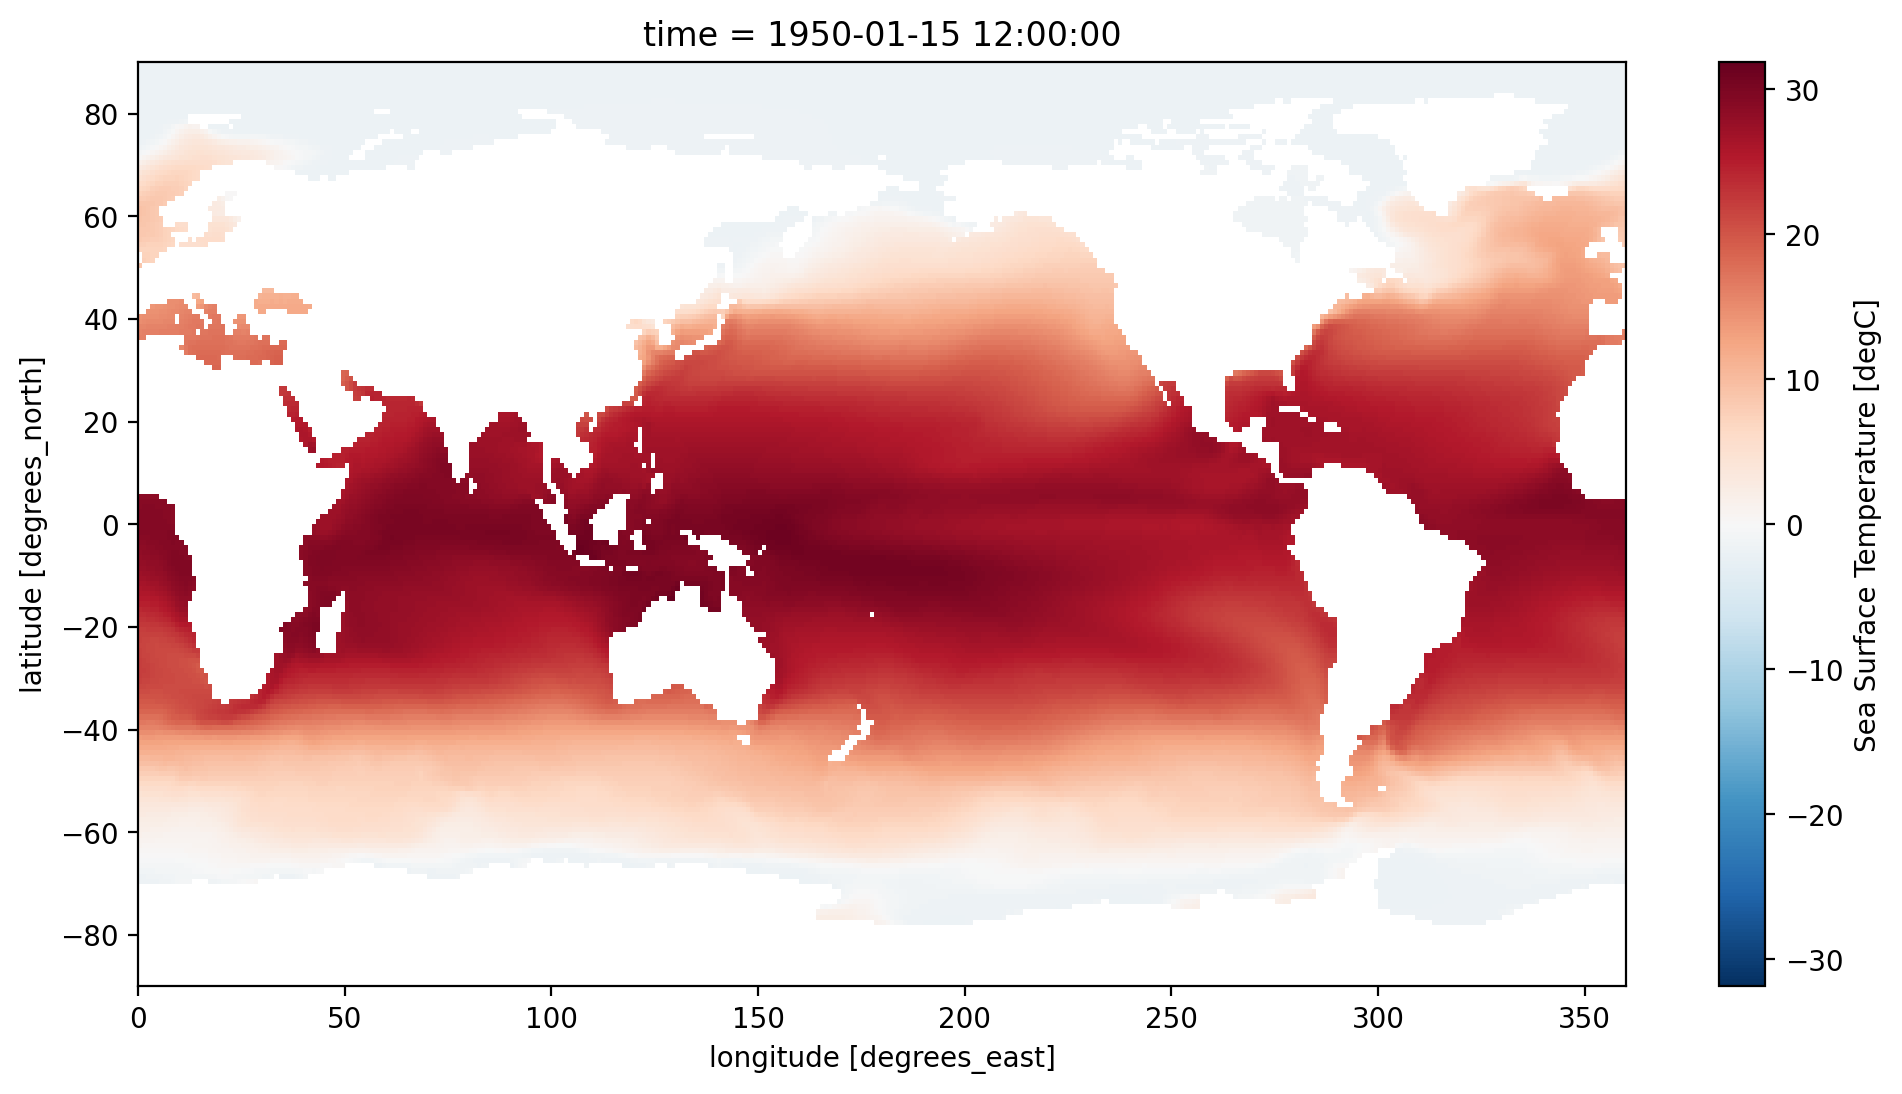

In [27]:
ds.tos.sel(time='1950-01').squeeze().plot()

Text(0.5, 1.0, 'Change in sea surface temperature\n(1985–2014 mean minus 1850–1900 mean)')

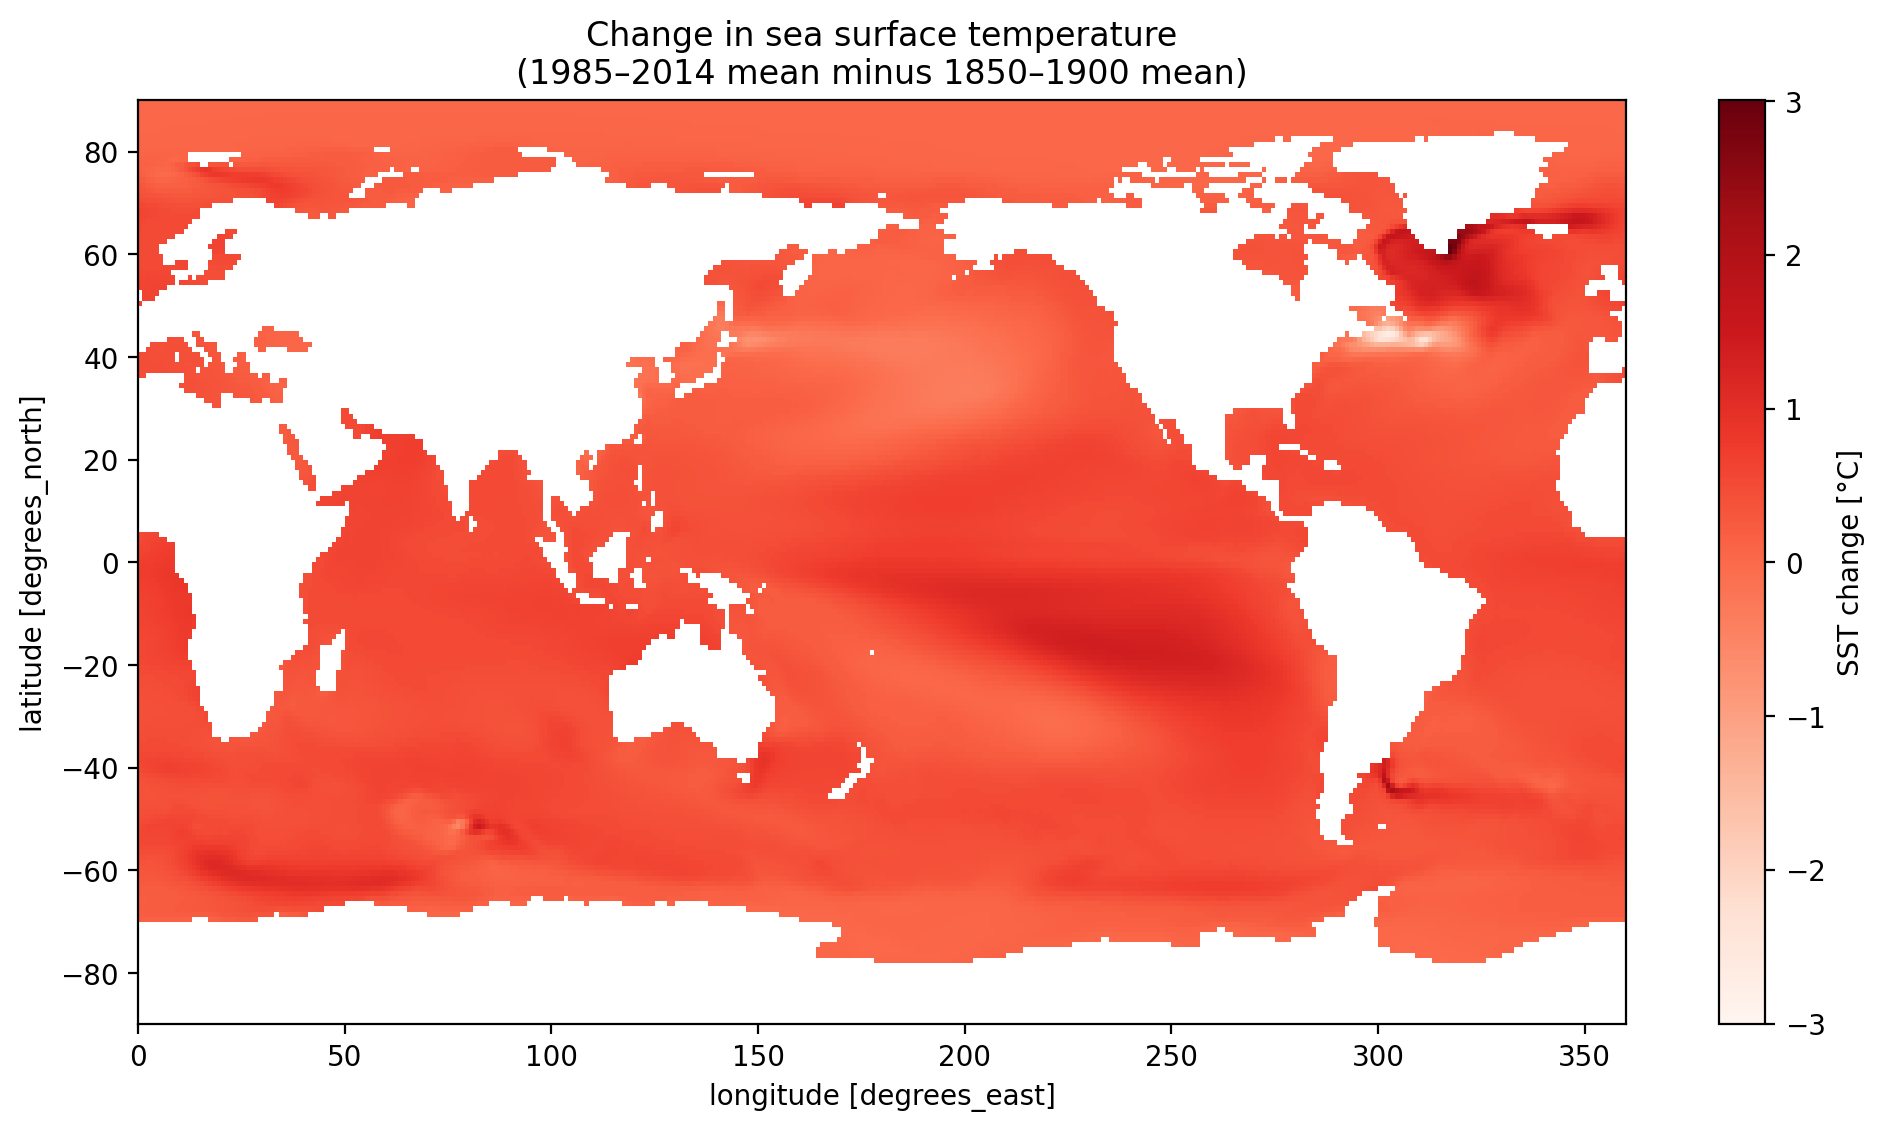

In [28]:
early = ds.tos.sel(time=slice('1850', '1900')).mean('time')
late  = ds.tos.sel(time=slice('1985', '2014')).mean('time')

change = (late - early).load()   # triggers the actual download/computation

change.plot(cmap='Reds', cbar_kwargs={'label': 'SST change [°C]'})
plt.title('Change in sea surface temperature\n(1985–2014 mean minus 1850–1900 mean)')

Text(0.5, 1.0, 'SST trend, 1850-2014 (red = warming, blue = cooling)')

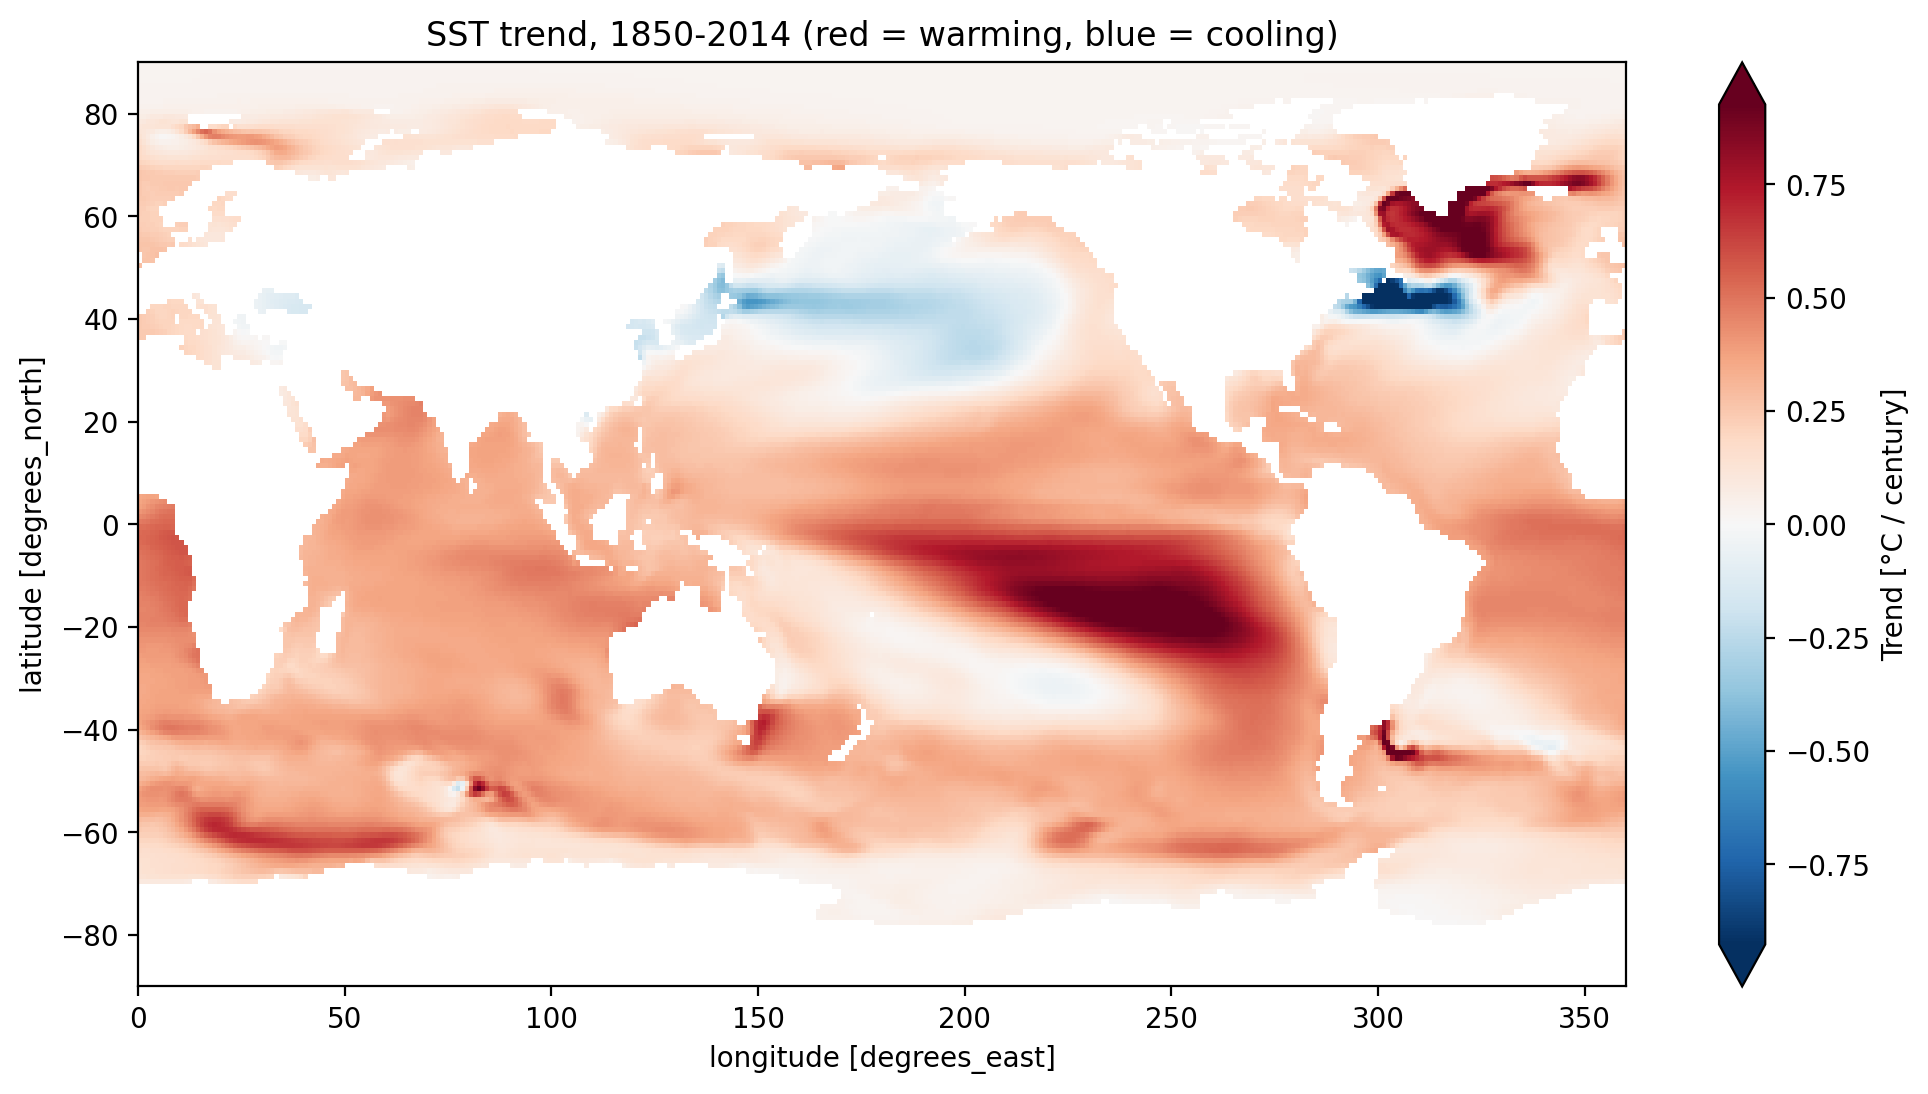

In [35]:
tos_annual = ds.tos.groupby('time.year').mean('time').load()
fit = tos_annual.polyfit('year', deg=1)
trend = fit.polyfit_coefficients.sel(degree=1) * 100   # °C per year -> °C per century

# symmetric limits so the same shade means the same magnitude on both sides of zero
vmax = float(abs(trend).quantile(0.99))

trend.plot(cmap='RdBu_r', center=0, vmin=-vmax, vmax=vmax,
           cbar_kwargs={'label': 'Trend [°C / century]'})
plt.title('SST trend, 1850-2014 (red = warming, blue = cooling)')

Text(0.01, 0.05, '↓ less fire-favorable')

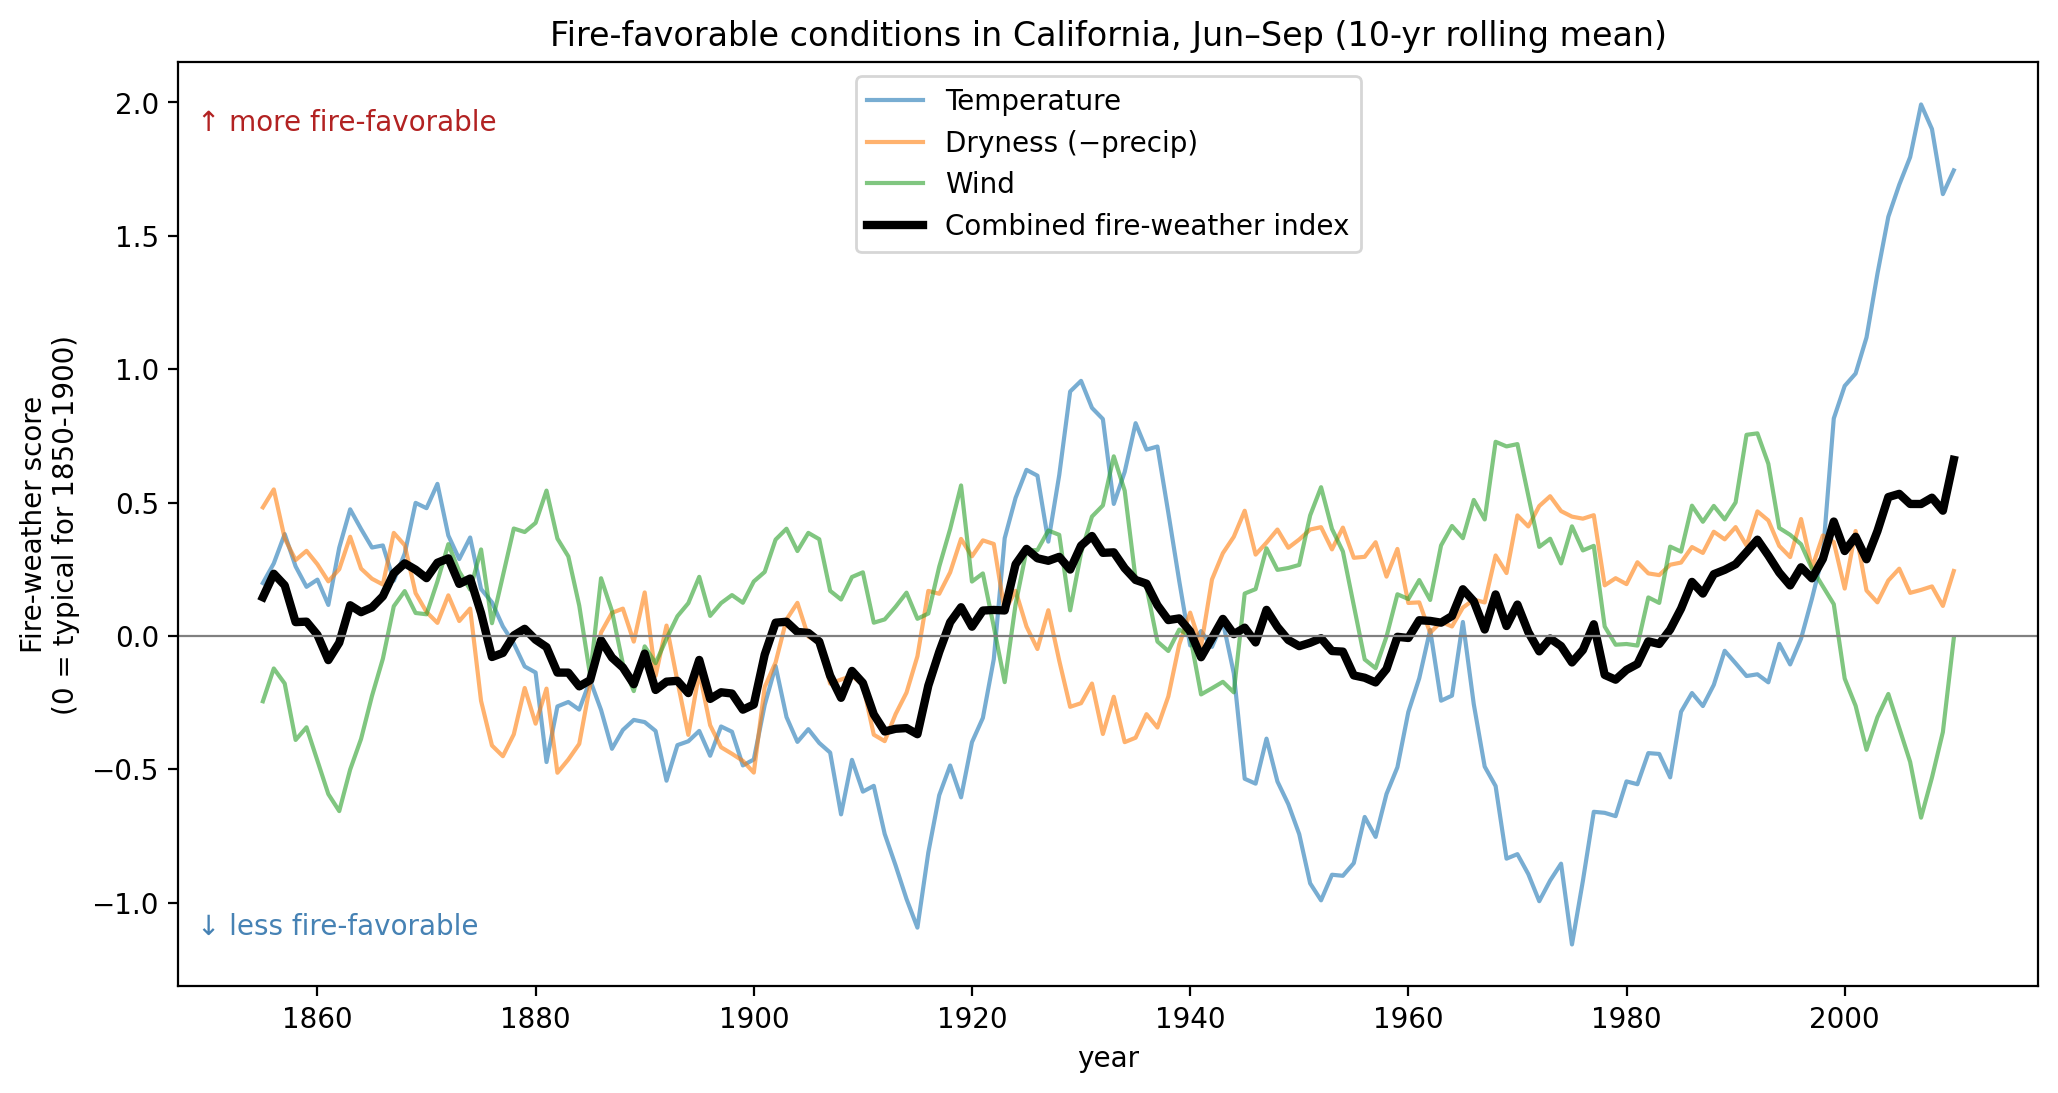

In [34]:
def load_var(var, source='CESM2', member='r1i1p1f1', exp='historical'):
    q = df.query("activity_id=='CMIP' & table_id=='Amon' & variable_id==@var "
                 "& experiment_id==@exp & source_id==@source & member_id==@member")
    return xr.open_zarr(gcs.get_mapper(q.zstore.iloc[0]), consolidated=True)[var]

def fire_season_mean(da, lat=(32, 42), lon=(235, 246), months=(6, 7, 8, 9)):
    # region (roughly California; CMIP longitudes run 0-360), summer months only
    sub = da.sel(lat=slice(*lat), lon=slice(*lon))
    sub = sub.where(sub['time.month'].isin(months), drop=True)
    w = np.cos(np.deg2rad(sub.lat))                       # area weighting
    regional = sub.weighted(w).mean(['lat', 'lon'])
    return regional.groupby('time.year').mean('time').load()

tas  = fire_season_mean(load_var('tas'))
pr   = fire_season_mean(load_var('pr'))
wind = fire_season_mean(load_var('sfcWind'))

def zscore(x, base=slice(1850, 1900)):
    ref = x.sel(year=base)
    return (x - ref.mean()) / ref.std()

z_tas, z_pr, z_wind = zscore(tas), zscore(pr), zscore(wind)

# fire-favorable = hotter, drier, windier
index = (z_tas - z_pr + z_wind) / 3

fig, ax = plt.subplots()
for z, label in [(z_tas, 'Temperature'), (-z_pr, 'Dryness (−precip)'), (z_wind, 'Wind')]:
    z.rolling(year=10, center=True).mean().plot(ax=ax, label=label, alpha=0.6)
index.rolling(year=10, center=True).mean().plot(ax=ax, color='k', lw=3, label='Combined fire-weather index')
ax.axhline(0, color='gray', lw=0.8)
ax.set_ylabel('Anomaly (std. dev. vs 1850–1900)')
ax.set_title('Fire-favorable conditions in California, Jun–Sep (10-yr rolling mean)')
ax.legend()
ax.set_ylabel('Fire-weather score\n(0 = typical for 1850-1900)')
ax.text(0.01, 0.95, '↑ more fire-favorable', transform=ax.transAxes, va='top', color='firebrick')
ax.text(0.01, 0.05, '↓ less fire-favorable', transform=ax.transAxes, va='bottom', color='steelblue')

Create a timeseries of global-average surface air temperature. For this we need the area weighting factor for each gridpoint.

In [15]:
df_area = df.query("variable_id == 'areacella' & source_id == 'CESM2'")
ds_area = xr.open_zarr(gcs.get_mapper(df_area.zstore.values[0]), consolidated=True)
ds_area

<xarray.Dataset> Size: 229kB
Dimensions:    (lat: 192, lon: 288, nbnd: 2)
Coordinates:
  * lat        (lat) float64 2kB -90.0 -89.06 -88.12 -87.17 ... 88.12 89.06 90.0
    lat_bnds   (lat, nbnd) float32 2kB ...
  * lon        (lon) float64 2kB 0.0 1.25 2.5 3.75 ... 355.0 356.2 357.5 358.8
    lon_bnds   (lon, nbnd) float32 2kB ...
Dimensions without coordinates: nbnd
Data variables:
    areacella  (lat, lon) float32 221kB ...
Attributes: (12/47)
    Conventions:            CF-1.7 CMIP-6.2
    activity_id:            CMIP
    branch_method:          no parent
    branch_time_in_child:   711385.0
    branch_time_in_parent:  0.0
    case_id:                38
    ...                     ...
    variable_id:            areacella
    variant_info:           f.e21.FHIST_BGC.f09_f09_mg17.CMIP6-AMIP.001 
\n
\...
    variant_label:          r1i1p1f1
    status:                 2019-11-04;created;by nhn2@columbia.edu
    netcdf_tracking_ids:    hdl:21.14100/23fa9dc3-4f8f-4943-b99b-58eb804c06f0
    version_id:             v20190218

In [16]:
total_area = ds_area.areacella.sum(dim=['lon', 'lat'])
ta_timeseries = (ds.tas * ds_area.areacella).sum(dim=['lon', 'lat']) / total_area
ta_timeseries

<xarray.DataArray (time: 1980)> Size: 8kB
array([285.2367 , 285.49353, 286.10147, ..., 288.3483 , 287.31396,
       286.56613], dtype=float32)
Coordinates:
  * time     (time) object 16kB 1850-01-15 12:00:00 ... 2014-12-15 12:00:00

By default the data are loaded lazily, as Dask arrays. Here we trigger computation explicitly.

In [17]:
ta_timeseries.load()

<xarray.DataArray (time: 1980)> Size: 8kB
array([285.2367 , 285.49353, 286.10147, ..., 288.3483 , 287.31396,
       286.56613], dtype=float32)
Coordinates:
  * time     (time) object 16kB 1850-01-15 12:00:00 ... 2014-12-15 12:00:00

Text(0.5, 1.0, 'Global Mean Surface Air Temperature')

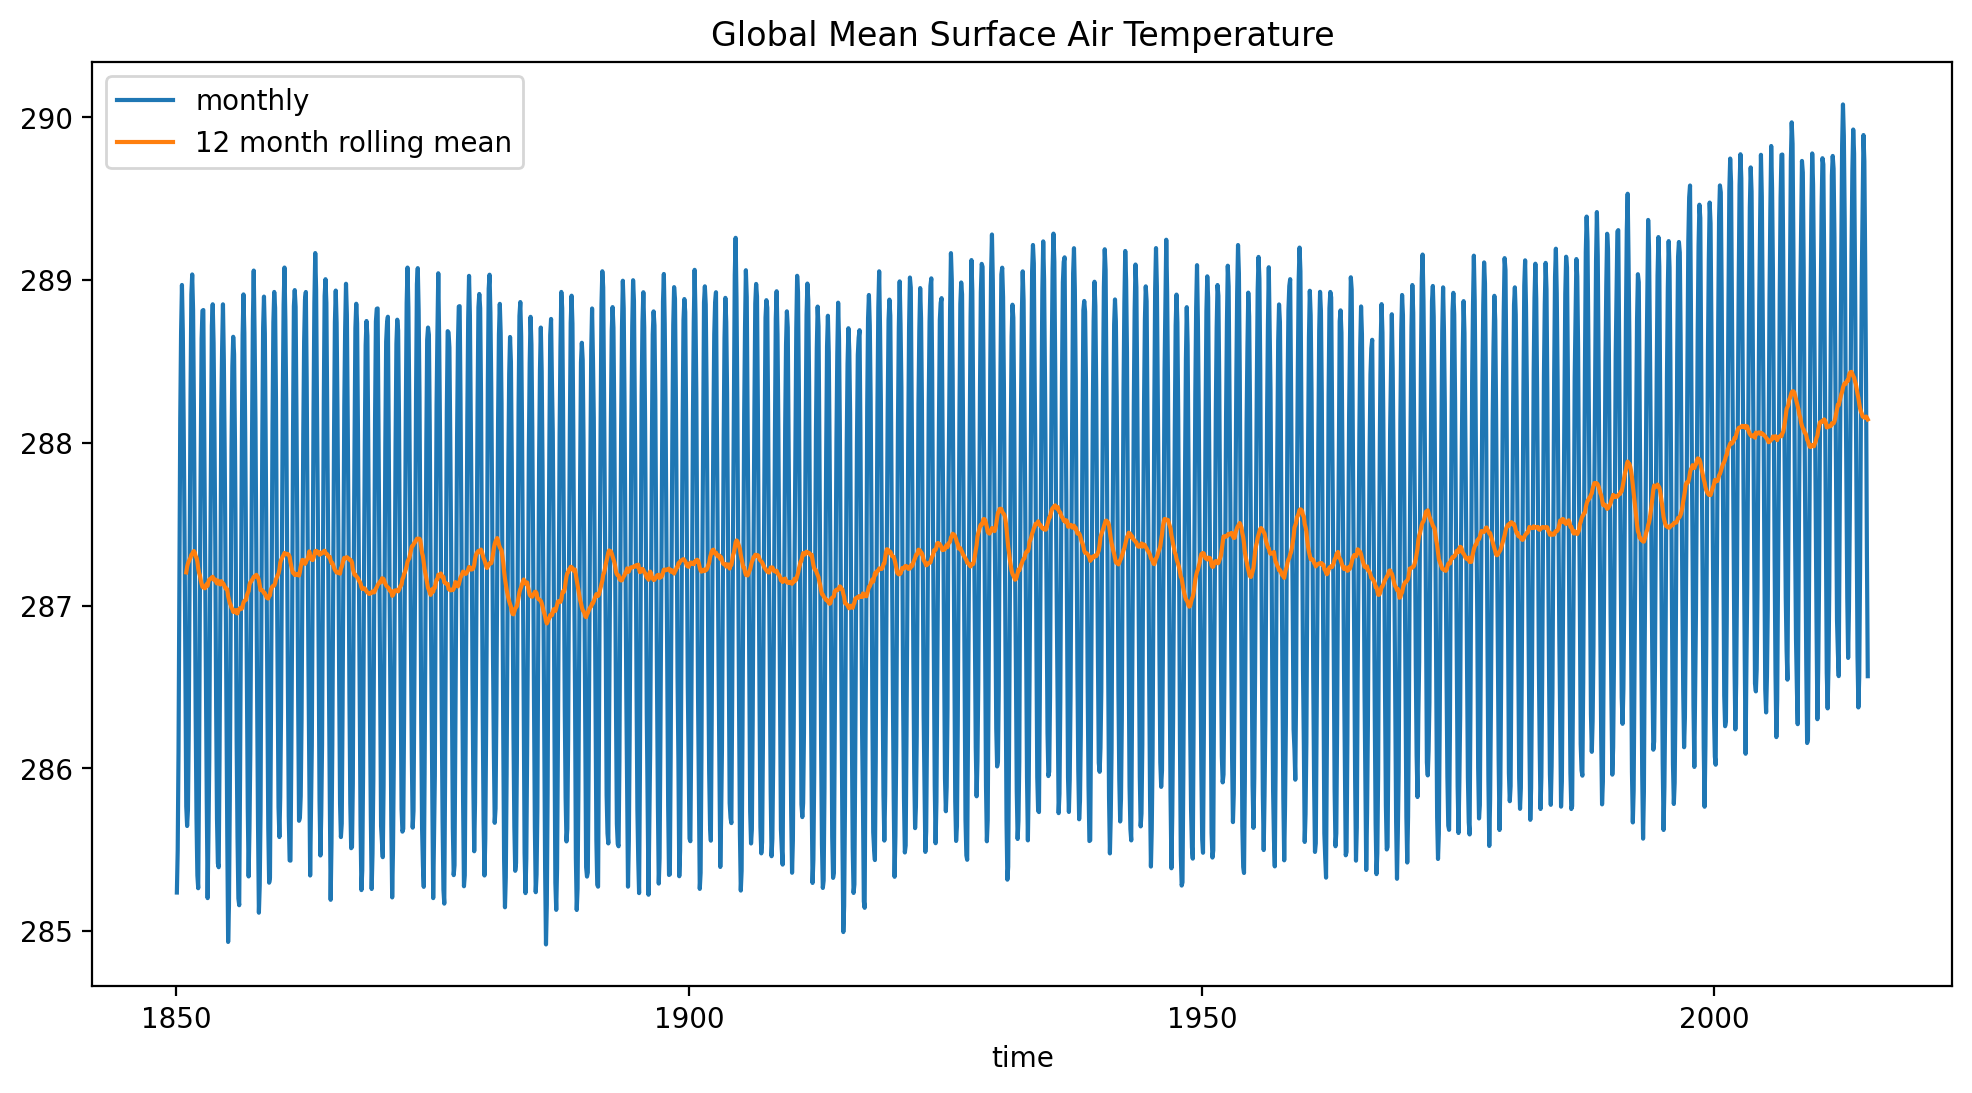

In [18]:
ta_timeseries.plot(label='monthly')
ta_timeseries.rolling(time=12).mean().plot(label='12 month rolling mean')
plt.legend()
plt.title('Global Mean Surface Air Temperature')

Or, we can select e.g. San Diego

In [19]:
sd_time_series = ds.tas.sel(lon=360-117.1611, lat=32.7157, method='nearest')

Text(0.5, 1.0, 'San Diego Surface Air Temperature')

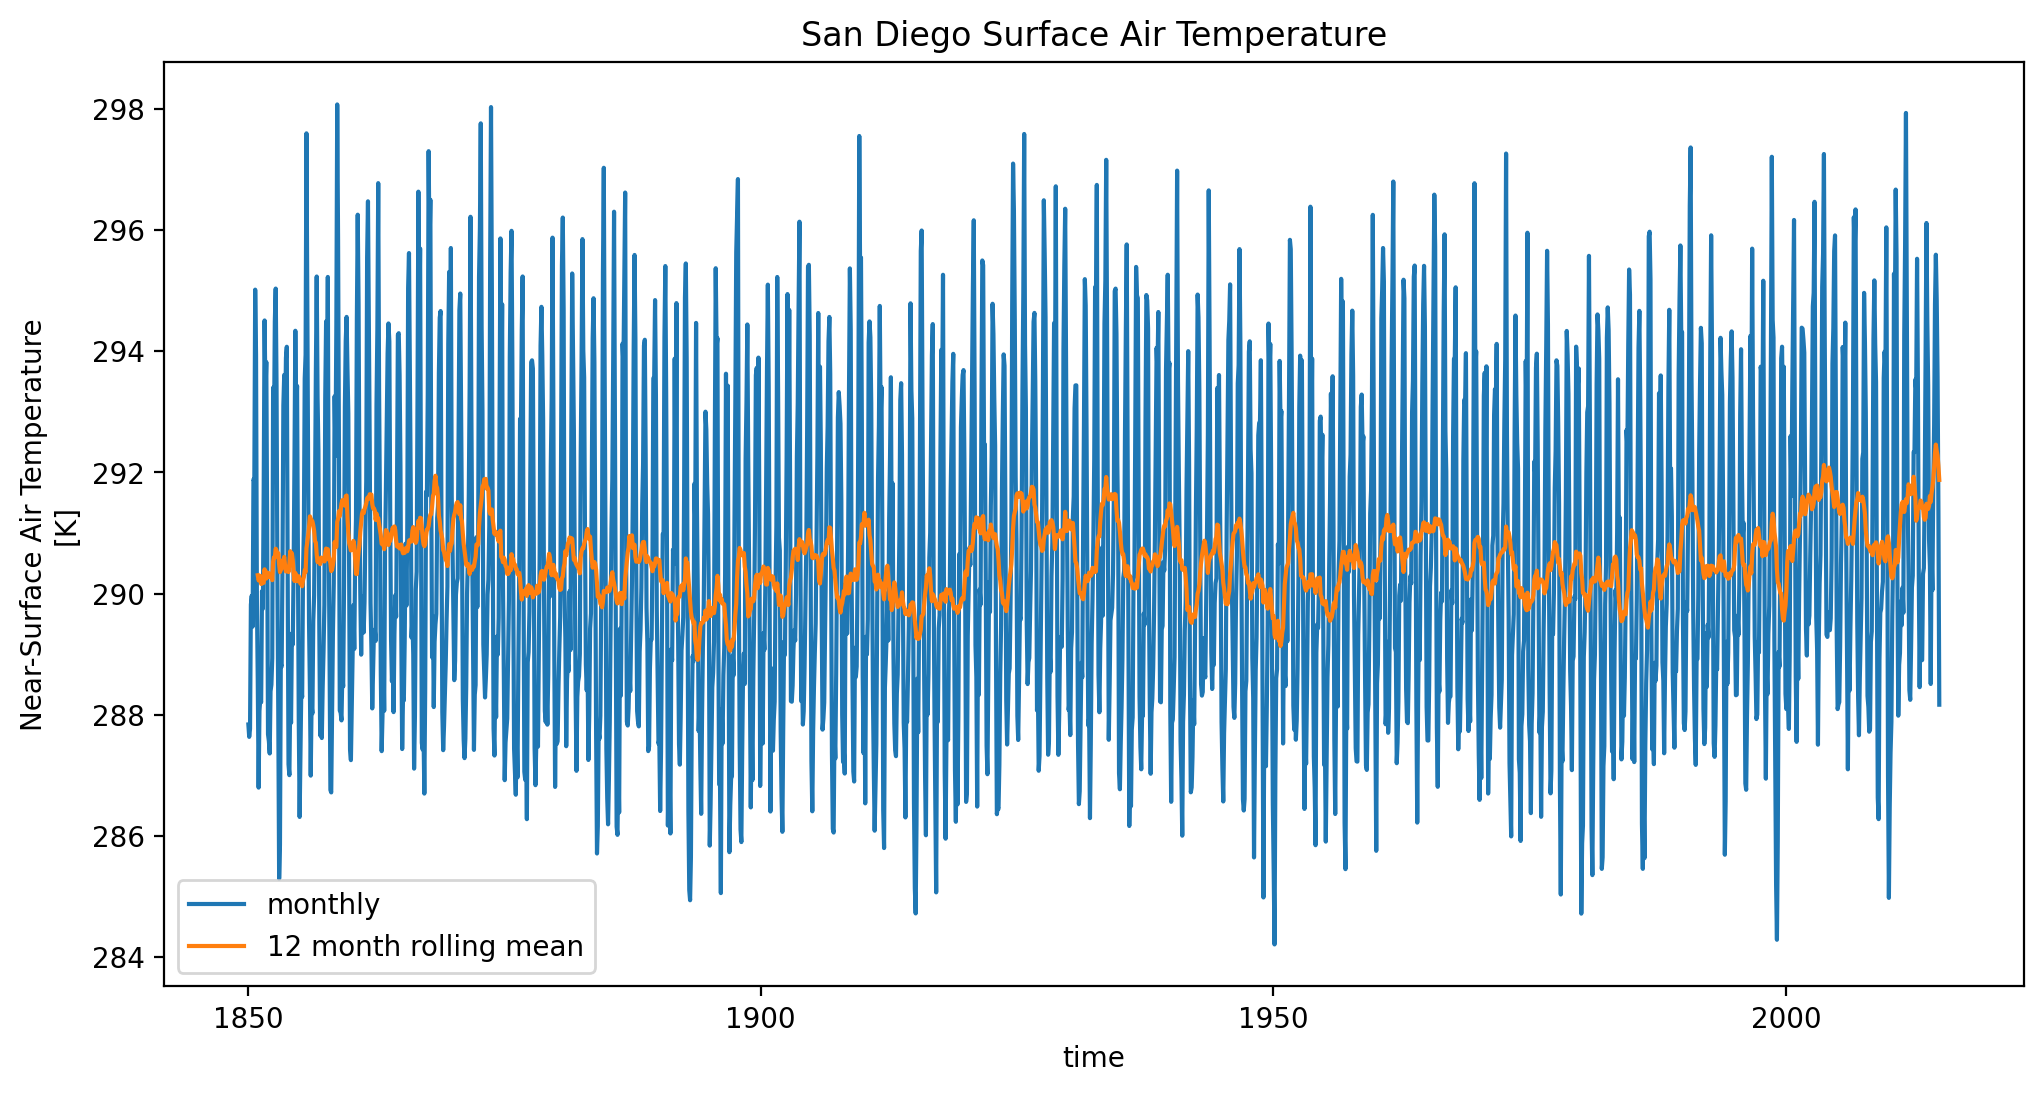

In [20]:
sd_time_series.plot(label='monthly')
sd_time_series.rolling(time=12).mean().plot(label='12 month rolling mean')
plt.legend()
plt.title('San Diego Surface Air Temperature')

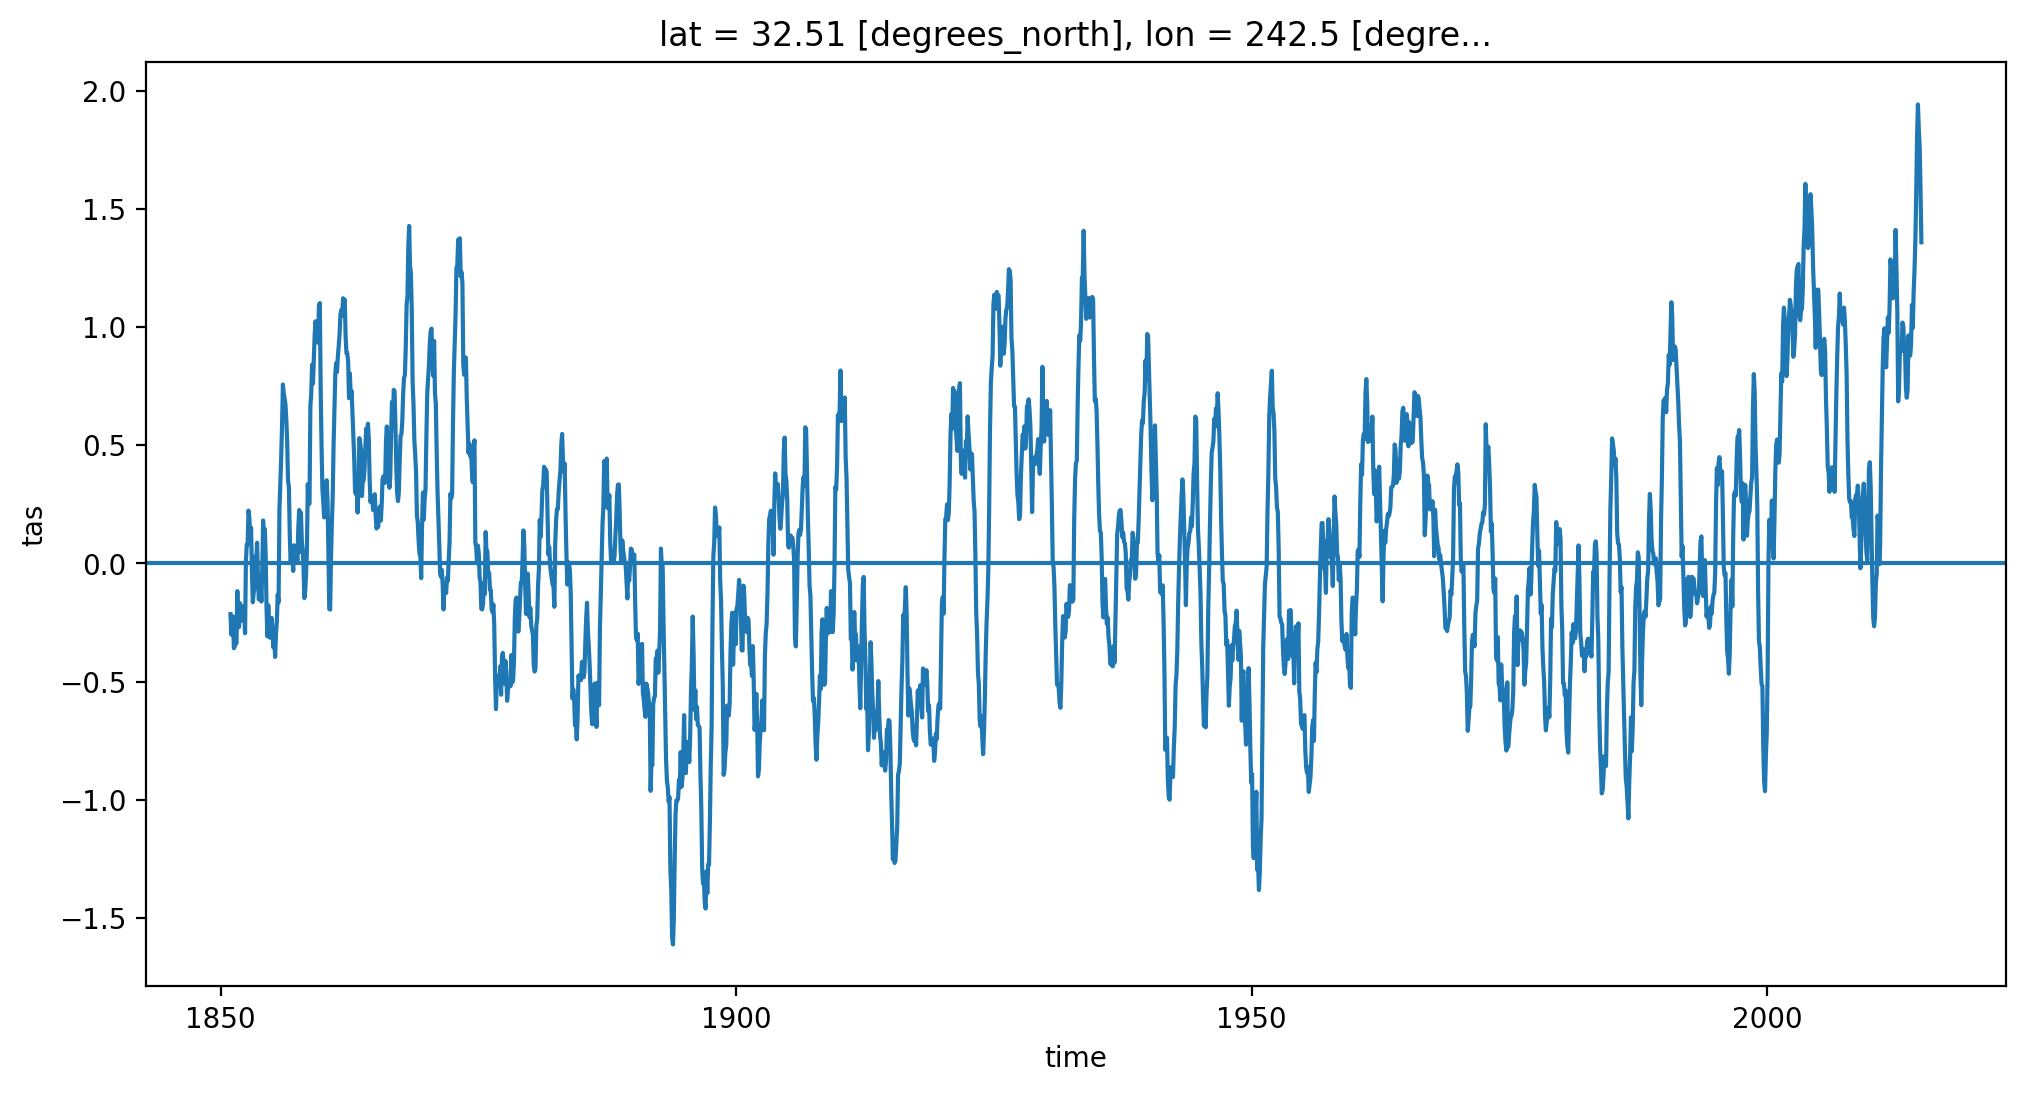

In [21]:
(sd_time_series.rolling(time=12).mean()-sd_time_series.sel(time=slice("1850","1900")).mean()).plot(label='12 month rolling mean')
plt.axhline(0.)